# Smart Shelf - Milestone 2, Task M2-T03: Sell-through risk factor

**Task card**

- Source for `current_stock` defined and documented first. The dataset has no `current_stock` column, so `initial_quantity` is the starting stock. It is **never** derived from outcome columns such as `units_sold` or `units_wasted`.
- `sell_through_risk = current_stock / sales_velocity`, computed and compared against `days_until_expiry`.
- Batches flagged **at-risk** where the ratio is greater than 1.
- Optional (must not delay M2): `distribution_hours` tried as an enrichment.

**How to read the feature.** `current_stock / sales_velocity` is *how many days it would take to sell the stock at the current speed*. Comparing it with `days_until_expiry` (days left before expiry) gives the ratio:

`sell_through_ratio = sell_through_risk / days_until_expiry`  ->  above 1 means the stock will probably **not** be sold before it expires.

| Output column | Meaning |
|---|---|
| `current_stock` | starting stock of the batch (`initial_quantity`) |
| `sell_through_risk` | days needed to sell the stock = `current_stock / sales_velocity_per_day` |
| `sell_through_ratio` | `sell_through_risk / days_until_expiry` (days left counted as at least 1) |
| `at_risk` | 1 if the ratio is above 1 |
| `risk_status` | `at_risk`, `ok`, `at_risk_zero_velocity` or `no_history`, so every flag can be traced |
| `sell_through_risk_card`, `at_risk_card` | same calculation with the card's raw `sales_velocity` (comparison only, Section 5) |

**Decisions** (each one is backed by a number computed below): 1) the stock source, 2) which velocity is the main one, 3) how zero velocity and zero days left are handled, 4) the optional `distribution_hours` enrichment stays a separate column and does not change the official flag.

## 0. Imports and loading the data

In [1]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)

DATA_PATH = Path("perishable_goods_management.csv")      # put the csv in the same folder as this notebook
df = pd.read_csv(DATA_PATH)
if "day_of_week" not in df.columns:                      # blank header in some copies of the file (see M1-T04)
    df = df.rename(columns={[c for c in df.columns if str(c).startswith("Unnamed")][0]: "day_of_week"})
# the dates come in two layouts depending on the copy of the file: 9/25/2024 (month/day/year) or 2024-09-25 (ISO)
for c in ["transaction_date", "expiration_date"]:
    is_iso = df[c].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}").all()
    df[c] = pd.to_datetime(df[c], format="%Y-%m-%d" if is_iso else "%m/%d/%Y", errors="raise")   # explicit format, no guessing
    print(f"{c}: parsed as", "YYYY-MM-DD" if is_iso else "M/D/YYYY")

required = ["record_id", "product_name", "store_id", "category", "transaction_date", "expiration_date", "shelf_life_days",
            "days_remaining_at_purchase", "days_until_expiry", "initial_quantity", "units_sold", "units_wasted",
            "waste_pct", "was_spoiled", "distribution_hours"]
assert not [c for c in required if c not in df.columns], "Missing columns: " + str([c for c in required if c not in df.columns])
assert len(df) == 100_000, "Unexpected number of rows"
df = df[[c for c in df.columns if c not in ("current_stock", "sell_through_risk")]]      # in case a processed copy is loaded
print(df.shape)

transaction_date: parsed as M/D/YYYY
expiration_date: parsed as M/D/YYYY
(100000, 42)


## 1. Source of `current_stock` (defined first, as the card requires)

The file has **no stock-on-hand column**. The only quantity known about a batch *before* it is sold is `initial_quantity`, the number of units received. So:

> **`current_stock = initial_quantity`** (the starting stock of the batch, at its `transaction_date`).

The rule that matters: `current_stock` must never be built from `units_sold`, `units_wasted`, `waste_pct`, `revenue` or any other result of the sale. The next cell shows why that is a real risk in this file, and that the choice is safe.

In [2]:
# 1) the file stores initial_quantity AND its two outcome parts, and they add up exactly
identity = (df["units_sold"] + df["units_wasted"] == df["initial_quantity"]).all()
print("units_sold + units_wasted == initial_quantity in every row:", identity)
print("-> stock could be 'rebuilt' from outcomes, which is the forbidden route. We read initial_quantity directly instead.")

# 2) quality of the chosen source
q = df["initial_quantity"]
print("\nmissing:", int(q.isna().sum()), "| zero or negative:", int((q <= 0).sum()),
      "| min / median / max:", q.min(), "/", q.median(), "/", q.max())

# 3) the source
df["current_stock"] = df["initial_quantity"]

# 4) is the source itself a leak? it should say almost nothing about spoilage on its own
print("\nAUC of current_stock vs was_spoiled:", round(roc_auc_score(df["was_spoiled"], df["current_stock"]), 3), "(0.5 = no signal)")
print("corr of current_stock with waste_pct:", round(df["current_stock"].corr(df["waste_pct"]), 3))

units_sold + units_wasted == initial_quantity in every row: True
-> stock could be 'rebuilt' from outcomes, which is the forbidden route. We read initial_quantity directly instead.

missing: 0 | zero or negative: 0 | min / median / max: 10 / 255.0 / 500



AUC of current_stock vs was_spoiled: 0.498 (0.5 = no signal)
corr of current_stock with waste_pct: -0.137


**Decision 1: `current_stock = initial_quantity`.** It is complete, always positive and known when the batch arrives. On its own it has almost no relation to spoilage (AUC near 0.5), so it is not a hidden outcome. The identity `units_sold + units_wasted = initial_quantity` is the reason for the rule: it makes it easy to rebuild stock from outcomes by mistake. We do not. The leakage test in Section 6.3 also proves that changing a batch's own outcomes does not change its own `sell_through_risk`.

## 2. Sales velocity (reused from M2-T02)

`sales_velocity` is computed exactly as in M2-T02: earlier batches only, same `product_name` x `store_id`, trailing 7 days, with the category-store fallback. The batch's own `units_sold` is never used. The function below is copied unchanged from that notebook so this one runs on its own. It returns two velocities:

- `sales_velocity` (the card's): batch totals added up over 7 days, divided by 7. This is **not** units per day, because `units_sold` is the total of a batch's whole shelf life (M2-T02, Decision 5).
- `sales_velocity_per_day`: the same earlier batches, each converted to units per day. This is the one a "days to sell out" calculation needs.

In [3]:
PAIR = ["product_name", "store_id"]
WINDOW = 7

PAIR = ["product_name", "store_id"]      # Decision 1
WINDOW = 7                               # Decision 3

def add_sales_velocity(data):
    # sort so that every product-store pair is in date order
    data = data.sort_values(PAIR + ["transaction_date", "record_id"]).reset_index(drop=True)

    # units per day of each batch over its own selling period (used for the extra velocity)
    data["batch_rate"] = data["units_sold"] / data["days_remaining_at_purchase"].clip(lower=1)

    # step 1: earlier batches of the same pair inside the window
    # closed="left" leaves the current day out, so the row's own units_sold is never counted
    roller = data.groupby(PAIR).rolling(f"{WINDOW}D", on="transaction_date", closed="left")
    sold = roller["units_sold"].sum()
    rate_sum = roller["batch_rate"].sum()
    batches = roller["units_sold"].count()

    # the groups come out in the same order as the sorted table, so the values can be put straight back
    # (this check makes sure that really is true)
    assert (sold.index.get_level_values("transaction_date") == data["transaction_date"].values).all()
    data["sold_last_7d"] = sold.fillna(0).values
    data["batches_in_window_7d"] = batches.fillna(0).astype(int).values
    window_rate = (rate_sum / batches).values                     # average rate of the batches in the window (NaN if none)

    # step 2: how many days of history does this pair have so far?
    first_date = data.groupby(PAIR)["transaction_date"].transform("min")
    data["pair_history_days"] = (data["transaction_date"] - first_date).dt.days

    # step 3: fallback = same category in the same store, earlier days only
    daily = (data.groupby(["category", "store_id", "transaction_date"])
                 .agg(units=("units_sold", "sum"), rates=("batch_rate", "sum"), n=("batch_rate", "size")).reset_index())
    daily = daily.sort_values(["category", "store_id", "transaction_date"])
    by_group = daily.groupby(["category", "store_id"])
    units_before = by_group["units"].cumsum() - daily["units"]       # everything sold on earlier days
    rates_before = by_group["rates"].cumsum() - daily["rates"]
    batches_before = by_group["n"].cumsum() - daily["n"]
    history_days = (daily["transaction_date"] - by_group["transaction_date"].transform("min")).dt.days
    daily["cat_store_velocity"] = units_before / history_days.clip(lower=7)
    daily["cat_store_rate"] = rates_before / batches_before.replace(0, np.nan)
    daily.loc[history_days == 0, ["cat_store_velocity", "cat_store_rate"]] = np.nan     # nothing earlier at all

    n_before = len(data)
    data = data.merge(daily[["category", "store_id", "transaction_date", "cat_store_velocity", "cat_store_rate"]],
                      on=["category", "store_id", "transaction_date"], how="left")
    assert len(data) == n_before          # the merge must not add or remove rows

    # step 4: own window if the pair has 7+ days of history AND at least one earlier batch in the window
    use_own = (data["pair_history_days"] >= WINDOW) & (data["batches_in_window_7d"] > 0)
    data["sales_velocity"] = np.where(use_own, data["sold_last_7d"] / WINDOW, data["cat_store_velocity"])
    data["sales_velocity_per_day"] = np.where(use_own, window_rate, data["cat_store_rate"])
    data["velocity_source"] = np.where(use_own, "product_store_7d",
                              np.where(data["cat_store_velocity"].notna(), "category_store_avg", "no_history"))
    return data

In [4]:
features = add_sales_velocity(df)
print(features.shape)
print(features["velocity_source"].value_counts().to_string())
print("\nzero velocity (earlier batches sold nothing):", int((features["sales_velocity_per_day"] == 0).sum()), "rows")
print("days_until_expiry == 0:", int((features["days_until_expiry"] == 0).sum()), "rows")

(100000, 52)
velocity_source
category_store_avg    74009
product_store_7d      25415
no_history              576

zero velocity (earlier batches sold nothing): 2027 rows
days_until_expiry == 0: 9088 rows


## 3. Compute `sell_through_risk` and the at-risk flag

```
sell_through_risk  = current_stock / sales_velocity_per_day         (days to sell the stock)
sell_through_ratio = sell_through_risk / max(days_until_expiry, 1)
at_risk            = sell_through_ratio > 1
```

**Decision 2: the main velocity is `sales_velocity_per_day`.** Stock is in units and days-to-sell needs a speed in units per day. The card's raw velocity adds batch totals of very different time scales, so dividing by it gives a number that is not in days (Section 5 shows the effect on the flag).

**Decision 3: edge cases.**

- *Velocity = 0 with stock in hand:* the stock cannot be sold at that speed, so the time to sell is infinite and the batch is flagged `at_risk_zero_velocity`. The ratio is capped (below) so the file stays finite.
- *`days_until_expiry` = 0:* a batch cannot be sold in less than one day (dates and velocity are in whole days), so days left are counted as at least 1. These rows are flagged when more than one day is needed.
- *No earlier data at all* (the first days of the file, 576 rows): velocity is empty, so the batch is `no_history` and gets no flag. It is not set to "ok", because we simply do not know.

In [5]:
RATIO_CAP = 10.0     # ratios above this are shown as 10 (the exact size no longer matters: it means 'far too slow')

def sell_through(data, velocity_col):
    v = data[velocity_col]
    days_left = data["days_until_expiry"].clip(lower=1)
    days_to_sell = data["current_stock"] / v.where(v > 0)                 # NaN where velocity is 0 or unknown
    ratio = (days_to_sell / days_left)
    status = np.select(
        [v.isna(), v == 0, ratio > 1],
        ["no_history", "at_risk_zero_velocity", "at_risk"], default="ok")
    ratio = ratio.where(v != 0, RATIO_CAP).clip(upper=RATIO_CAP)          # zero velocity -> capped ratio
    at_risk = pd.Series(np.where(v.isna(), np.nan, np.isin(status, ["at_risk", "at_risk_zero_velocity"]).astype(float)), index=data.index)
    return days_to_sell, ratio, at_risk, status

features["sell_through_risk"], features["sell_through_ratio"], features["at_risk"], features["risk_status"] = \
    sell_through(features, "sales_velocity_per_day")
features["days_gap"] = features["days_until_expiry"] - features["sell_through_risk"]        # positive = enough time
(features["sell_through_risk_card"], features["sell_through_ratio_card"],
 features["at_risk_card"], features["risk_status_card"]) = sell_through(features, "sales_velocity")

print(features["risk_status"].value_counts().to_string())
known = features["at_risk"].notna()
print("\nat-risk share among batches with a velocity: %.1f %%" % (100 * features.loc[known, "at_risk"].mean()))
features[["record_id", "category", "current_stock", "sales_velocity_per_day", "sell_through_risk",
          "days_until_expiry", "sell_through_ratio", "at_risk", "risk_status"]].head(8).round(2)

risk_status
at_risk                  56576
ok                       40821
at_risk_zero_velocity     2027
no_history                 576

at-risk share among batches with a velocity: 58.9 %


,record_id,category,current_stock,sales_velocity_per_day,sell_through_risk,days_until_expiry,sell_through_ratio,at_risk,risk_status
0,32376,Pharmaceuticals,298,0.42,702.02,196,3.58,1.0,at_risk
1,53379,Pharmaceuticals,74,0.53,140.48,135,1.04,1.0,at_risk
2,18356,Pharmaceuticals,124,0.37,335.53,300,1.12,1.0,at_risk
3,7450,Pharmaceuticals,23,0.54,42.41,485,0.09,0.0,ok
4,90801,Pharmaceuticals,46,0.49,93.01,259,0.36,0.0,ok
5,44891,Pharmaceuticals,133,0.82,161.43,540,0.30,0.0,ok
6,439,Pharmaceuticals,30,0.25,122.03,560,0.22,0.0,ok
7,27620,Pharmaceuticals,106,0.73,144.60,332,0.44,0.0,ok


In [6]:
print(features["sell_through_risk"].describe().round(2).to_string())
print()
print(features["sell_through_ratio"].describe().round(2).to_string())

count    97397.00
mean        70.46
std        345.62
min          0.03
25%          3.15
50%          7.53
75%         22.56
max      39168.00

count    99424.00
mean         2.18
std          2.49
min          0.01
25%          0.60
50%          1.26
75%          2.63
max         10.00


## 4. Compared against `days_until_expiry`

                 median_days_to_sell  median_days_until_expiry  median_ratio  at_risk_share  spoiled_rate   rows
category                                                                                                        
Frozen_Meals                  236.88                     173.0          1.56           0.67          0.17   9867
Meat                            5.78                       4.0          1.43           0.65          0.21   9998
Bakery                          3.48                       2.0          1.44           0.63          0.18   9985
Seafood                         3.48                       2.0          1.41           0.63          0.21   9902
Ready_to_Eat                    2.22                       1.0          1.38           0.61          0.22   9990
Deli                            7.08                       6.0          1.25           0.60          0.19   9935
Beverages                      16.22                      14.0          1.19           0.57     

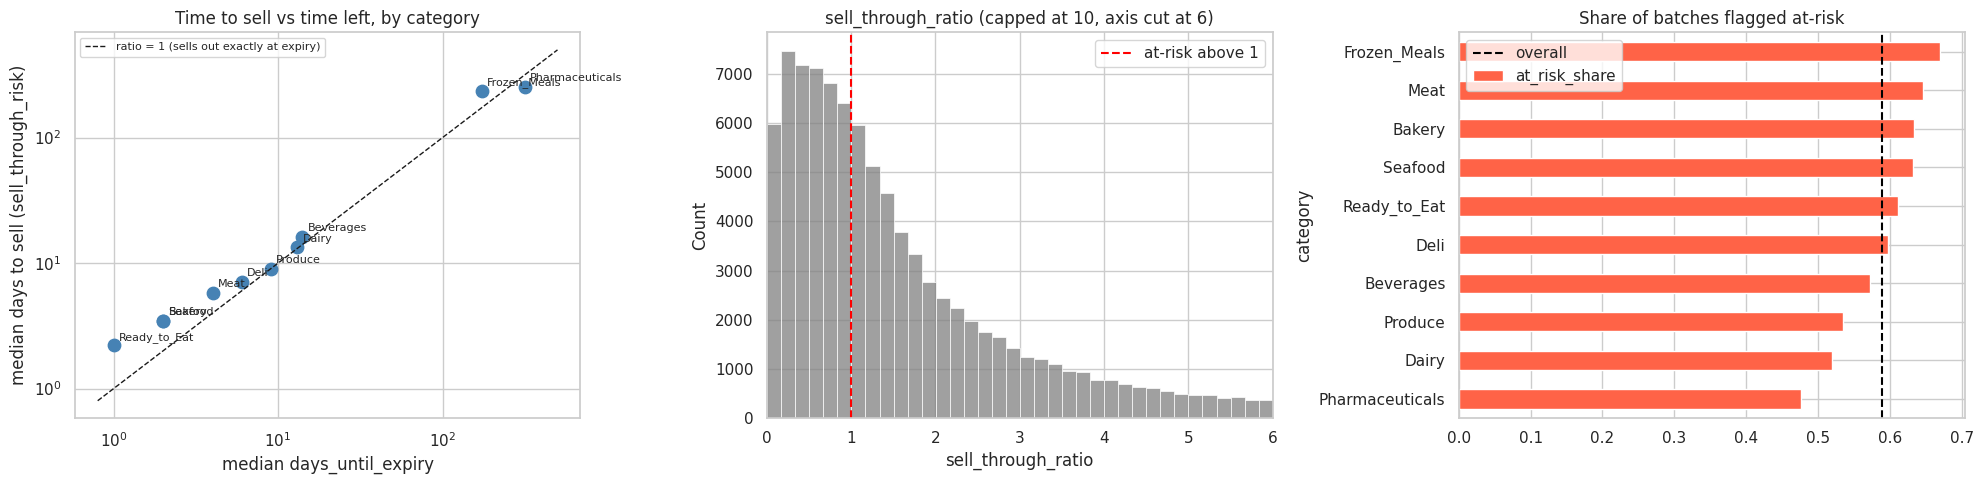

In [7]:
cat = (features[known].groupby("category")
       .agg(median_days_to_sell=("sell_through_risk", "median"), median_days_until_expiry=("days_until_expiry", "median"),
            median_ratio=("sell_through_ratio", "median"), at_risk_share=("at_risk", "mean"),
            spoiled_rate=("was_spoiled", "mean"), rows=("at_risk", "size"))
       .sort_values("at_risk_share", ascending=False))
print(cat.round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# (a) days to sell vs days left, one dot per category (medians), on a log scale
ax = axes[0]
ax.scatter(cat["median_days_until_expiry"], cat["median_days_to_sell"], s=80, color="steelblue")
for n, r in cat.iterrows():
    ax.annotate(n, (r["median_days_until_expiry"], r["median_days_to_sell"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
lim = [0.8, 500]; ax.plot(lim, lim, "k--", lw=1, label="ratio = 1 (sells out exactly at expiry)")
ax.set(xscale="log", yscale="log", xlabel="median days_until_expiry", ylabel="median days to sell (sell_through_risk)",
       title="Time to sell vs time left, by category"); ax.legend(fontsize=8)

# (b) ratio distribution
ax = axes[1]
sns.histplot(features.loc[known, "sell_through_ratio"], bins=60, ax=ax, color="grey")
ax.axvline(1, color="red", ls="--", label="at-risk above 1"); ax.set_xlim(0, 6)
ax.set(title="sell_through_ratio (capped at 10, axis cut at 6)"); ax.legend()

# (c) at-risk share by category
cat["at_risk_share"].sort_values().plot(kind="barh", ax=axes[2], color="tomato")
axes[2].axvline(features.loc[known, "at_risk"].mean(), color="black", ls="--", label="overall")
axes[2].set(title="Share of batches flagged at-risk"); axes[2].legend()
plt.tight_layout(); plt.savefig("figures/m2_t03_sell_through_risk.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading.** In most categories the median time to sell the stock is close to the time left before expiry (points near the dashed line), so the ratio sits around 1 for a typical batch. This is expected: a batch usually sells most of its stock over roughly its own shelf life. Two consequences:

- The "ratio > 1" rule is a **coarse** flag, because the threshold lies close to the middle of the distribution. About 59% of the batches with a velocity are flagged, far more than the 19% that actually spoil. Frozen_Meals, Meat, Bakery and Seafood are flagged most (63 to 67%), Pharmaceuticals least (48%).
- The ratio is more useful as a **graded score** (how far above 1) than as a yes/no. Section 5 checks whether higher ratios really go with more spoilage and waste.

## 5. Does the flag carry signal? (sanity check only)

The outcomes are used here **only to judge the feature**, never to build it.

                                               AUC vs was_spoiled  Spearman with waste_pct
feature                                                                                   
sell_through_ratio (per-day velocity, main)                 0.505                    0.006
sell_through_ratio_card (card's raw velocity)               0.513                   -0.113
days_gap (days_until_expiry - days to sell)                 0.500                   -0.003

Spoilage rate and waste_pct by flag:
                        rows  spoiled_rate  mean_waste_pct
risk_status                                               
at_risk                56576         0.196          20.501
at_risk_zero_velocity   2027         0.190          44.035
ok                     40821         0.193          24.406

flag with the card's raw velocity: at-risk share = 41.1 %
agreement between the two flags: 72.9 %

By ratio band:
                        rows  spoiled_rate  mean_waste_pct
sell_through_ratio                    

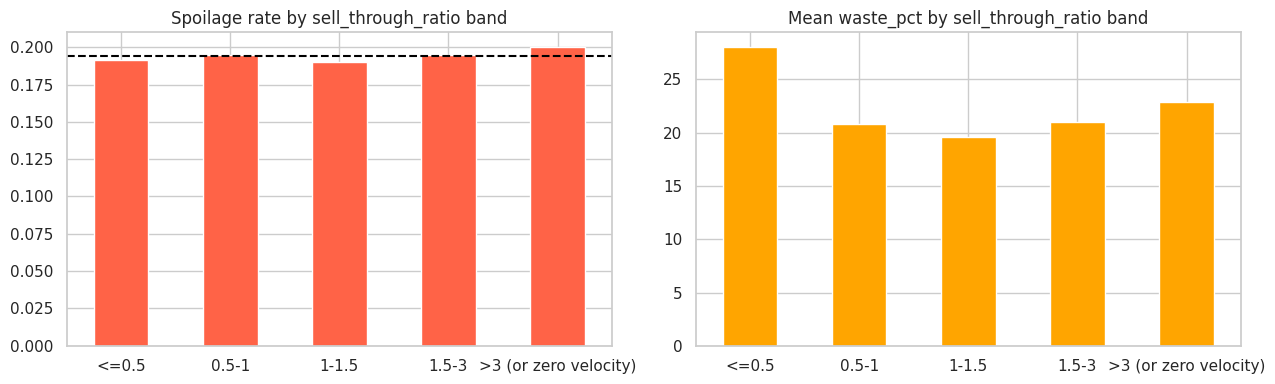

In [8]:
k = features[known]
rows = []
for name, col in [("sell_through_ratio (per-day velocity, main)", "sell_through_ratio"),
                  ("sell_through_ratio_card (card's raw velocity)", "sell_through_ratio_card"),
                  ("days_gap (days_until_expiry - days to sell)", "days_gap")]:
    ok = k[col].notna()
    rows.append({"feature": name,
                 "AUC vs was_spoiled": roc_auc_score(k.loc[ok, "was_spoiled"], k.loc[ok, col]),
                 "Spearman with waste_pct": stats.spearmanr(k.loc[ok, col], k.loc[ok, "waste_pct"])[0]})
print(pd.DataFrame(rows).set_index("feature").round(3).to_string())

print("\nSpoilage rate and waste_pct by flag:")
print(k.groupby("risk_status").agg(rows=("was_spoiled", "size"), spoiled_rate=("was_spoiled", "mean"), mean_waste_pct=("waste_pct", "mean")).round(3).to_string())
print("\nflag with the card's raw velocity: at-risk share = %.1f %%" % (100 * features["at_risk_card"].mean()))
print("agreement between the two flags: %.1f %%" % (100 * (features.loc[known, "at_risk"] == features.loc[known, "at_risk_card"]).mean()))

# graded view: spoilage and waste by ratio band
bands = pd.cut(k["sell_through_ratio"], [0, 0.5, 1, 1.5, 3, 10.01], labels=["<=0.5", "0.5-1", "1-1.5", "1.5-3", ">3 (or zero velocity)"])
by_band = k.groupby(bands, observed=True).agg(rows=("was_spoiled", "size"), spoiled_rate=("was_spoiled", "mean"), mean_waste_pct=("waste_pct", "mean"))
print("\nBy ratio band:"); print(by_band.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_band["spoiled_rate"].plot(kind="bar", ax=axes[0], color="tomato", rot=0); axes[0].axhline(k["was_spoiled"].mean(), color="black", ls="--")
axes[0].set(title="Spoilage rate by sell_through_ratio band", xlabel=""); 
by_band["mean_waste_pct"].plot(kind="bar", ax=axes[1], color="orange", rot=0)
axes[1].set(title="Mean waste_pct by sell_through_ratio band", xlabel="")
plt.tight_layout(); plt.savefig("figures/m2_t03_ratio_vs_outcomes.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading (honest result).**

- **No spoilage signal:** AUC is about 0.505 and the spoilage rate is 19.6% for flagged batches against 19.3% for the rest. The ratio bands are flat (19.0% to 20.0%). This matches the Milestone 1 finding that single inputs are weak, and the M2-T02 finding that velocity is mostly a category signal here.
- **Waste goes the "wrong" way:** flagged batches have a *lower* mean `waste_pct` (21.3% vs 24.4%; 20.5% if zero-velocity batches are left out), and the lowest ratio band has the highest waste (28%). The likely reason is that the ratio grows with `current_stock`, and in this data bigger batches have a lower waste percentage (correlation -0.137 in Section 1). So the sign is driven by batch size, not by a real "safe" effect. Zero-velocity batches do have much higher waste (44%), which is the one pattern that agrees with the idea.
- **Choice of velocity:** the card's raw velocity flags 41% of batches and agrees with the main flag on only 73% of rows, because it is not in units per day.
- **Use:** the feature is a sell-out logic input for Milestone 3 (markdown timing, waste cost), not a stand-alone spoilage predictor. It should not be presented as one.

## 6. Validation

### 6.1 Formula check by hand

In [9]:
s = features[known & (features["sales_velocity_per_day"] > 0)].sample(500, random_state=1)
by_hand_days = s["initial_quantity"] / s["sales_velocity_per_day"]
by_hand_ratio = by_hand_days / np.maximum(s["days_until_expiry"], 1)
assert np.allclose(by_hand_days, s["sell_through_risk"])
assert np.allclose(np.minimum(by_hand_ratio, RATIO_CAP), s["sell_through_ratio"])
assert ((by_hand_ratio > 1).astype(float) == s["at_risk"]).all()
assert (s["current_stock"] == s["initial_quantity"]).all()
print("500 random rows recalculated by hand: sell_through_risk, ratio, flag and stock all match.")
print("zero-velocity rows all flagged at-risk:", bool((features.loc[features['sales_velocity_per_day'] == 0, 'at_risk'] == 1).all()))
print("no_history rows have no flag:", bool(features.loc[features['risk_status'] == 'no_history', 'at_risk'].isna().all()))
print("negative values:", int((features['sell_through_risk'] < 0).sum()), "| ratio above cap:", int((features['sell_through_ratio'] > RATIO_CAP).sum()))

500 random rows recalculated by hand: sell_through_risk, ratio, flag and stock all match.
zero-velocity rows all flagged at-risk: True
no_history rows have no flag: True
negative values: 0 | ratio above cap: 0


### 6.2 The flag is exactly the rule "ratio above 1"

In [10]:
rule = (features.loc[known, "sell_through_ratio"] > 1)
zero = features.loc[known, "risk_status"] == "at_risk_zero_velocity"
print("flag == (ratio > 1) for every row with a velocity > 0:", bool(((features.loc[known, 'at_risk'] == 1) == (rule | zero)).all()))
print("rows at exactly ratio = 1 (not flagged, since the rule is '> 1'):", int((features["sell_through_ratio"] == 1).sum()))

flag == (ratio > 1) for every row with a velocity > 0: True
rows at exactly ratio = 1 (not flagged, since the rule is '> 1'): 13


### 6.3 Leakage test

If the batch's own outcomes are really not used, then changing its own `units_sold` and `units_wasted` must **not** change its own `current_stock`, `sell_through_risk` or flag. Later batches may change, since they legitimately use earlier sales. The test sets the outcomes of one batch per category-store group to extreme values and recomputes everything from scratch.

In [11]:
cols = ["record_id", "product_name", "store_id", "category", "transaction_date", "units_sold", "units_wasted",
        "days_remaining_at_purchase", "days_until_expiry", "initial_quantity"]
original = df[cols].copy()
changed_ids = original.groupby(["category", "store_id"]).sample(1, random_state=0)["record_id"]

altered = original.copy()
mask = altered["record_id"].isin(changed_ids)
altered.loc[mask, "units_sold"] = 1_000_000
altered.loc[mask, "units_wasted"] = 7_777_777

def full_pipeline(d):
    d = d.copy(); d["current_stock"] = d["initial_quantity"]
    d = add_sales_velocity(d)
    d["sell_through_risk"], d["sell_through_ratio"], d["at_risk"], d["risk_status"] = sell_through(d, "sales_velocity_per_day")
    return d.set_index("record_id")

before = full_pipeline(original); after = full_pipeline(altered).loc[before.index]
is_changed = before.index.isin(changed_ids)
for col in ["current_stock", "sell_through_risk", "sell_through_ratio"]:
    same = np.isclose(before[col], after[col], equal_nan=True)
    print(f"{col:20s} own value changed in {(~same[is_changed]).sum()} changed batches (must be 0) | other batches that changed: {(~same[~is_changed]).sum()}")
same_flag = (before["risk_status"] == after["risk_status"]).to_numpy()
print("risk_status          own value changed in", int((~same_flag[is_changed]).sum()), "changed batches (must be 0)")
assert (np.isclose(before.loc[is_changed, "sell_through_risk"], after.loc[is_changed, "sell_through_risk"], equal_nan=True)).all()
assert same_flag[is_changed].all()

current_stock        own value changed in 0 changed batches (must be 0) | other batches that changed: 0
sell_through_risk    own value changed in 0 changed batches (must be 0) | other batches that changed: 35561
sell_through_ratio   own value changed in 0 changed batches (must be 0) | other batches that changed: 35561
risk_status          own value changed in 0 changed batches (must be 0)


`current_stock` does not move at all (it is read from `initial_quantity`), and the changed batches keep their own `sell_through_risk` and flag. Other batches do change, which proves the test is sensitive and that later batches really use earlier sales.

### 6.4 Row and key checks

In [12]:
print("rows in df:", len(df), "| rows in features:", len(features), "| record_id unique:", features["record_id"].is_unique)
print("current_stock missing:", int(features["current_stock"].isna().sum()))
print("sell_through_risk missing:", int(features["sell_through_risk"].isna().sum()),
      "(= no_history rows %d + zero-velocity rows %d)" % ((features["risk_status"] == "no_history").sum(), (features["risk_status"] == "at_risk_zero_velocity").sum()))

rows in df: 100000 | rows in features: 100000 | record_id unique: True
current_stock missing: 0
sell_through_risk missing: 2603 (= no_history rows 576 + zero-velocity rows 2027)


## 7. Optional: `distribution_hours` as an enrichment

Time spent in distribution reduces the time a product is actually on sale. A simple try: shorten the days left by the distribution time, `effective_days_left = days_until_expiry - distribution_hours / 24` (at least 1), and recompute the ratio. This is **kept as separate columns** and does **not** change the official flag. It is only used if it clearly helps.

In [13]:
print(features["distribution_hours"].describe().round(1).to_string())
eff_days = (features["days_until_expiry"] - features["distribution_hours"] / 24).clip(lower=1)
features["sell_through_ratio_dist"] = (features["sell_through_risk"] / eff_days).where(features["sales_velocity_per_day"] != 0, RATIO_CAP).clip(upper=RATIO_CAP)
features["at_risk_dist"] = np.where(features["sales_velocity_per_day"].isna(), np.nan, (features["sell_through_ratio_dist"] > 1).astype(float))

k = features[features["at_risk"].notna()]
print("\nat-risk share  main: %.1f %%  |  with distribution time: %.1f %%" % (100 * k["at_risk"].mean(), 100 * k["at_risk_dist"].mean()))
print("flags that change: %.1f %% of rows" % (100 * (k["at_risk"] != k["at_risk_dist"]).mean()))
res = []
for col in ["sell_through_ratio", "sell_through_ratio_dist"]:
    res.append({"version": col, "AUC vs was_spoiled": roc_auc_score(k["was_spoiled"], k[col]),
                "Spearman with waste_pct": stats.spearmanr(k[col], k["waste_pct"])[0]})
print(pd.DataFrame(res).set_index("version").round(4).to_string())

count    100000.0
mean         38.0
std          19.6
min           4.0
25%          21.1
50%          38.0
75%          55.0
max          72.0

at-risk share  main: 58.9 %  |  with distribution time: 66.4 %
flags that change: 7.4 % of rows


                         AUC vs was_spoiled  Spearman with waste_pct
version                                                             
sell_through_ratio                   0.5047                   0.0056
sell_through_ratio_dist              0.5072                  -0.0113


**Reading.** The enrichment changes 7.4% of the flags and raises the at-risk share from 58.9% to 66.4%, because it only ever shortens the time left. AUC moves by 0.0025 and the waste correlation by about 0.017, which is too small to count as useful signal in this file. **Decision 4: it is kept as an optional pair of columns (`sell_through_ratio_dist`, `at_risk_dist`) but the official `at_risk` flag stays as defined by the card.** This part was quick and does not delay M2.

## 8. Save the new columns

In [14]:
out = features[["record_id", "current_stock", "sell_through_risk", "sell_through_ratio", "days_gap", "at_risk", "risk_status",
                "sell_through_risk_card", "sell_through_ratio_card", "at_risk_card",
                "sell_through_ratio_dist", "at_risk_dist"]].sort_values("record_id")
out.to_csv("m2_t03_features.csv", index=False)

summary = {
    "task": "M2-T03", "current_stock_source": "initial_quantity (never derived from units_sold / units_wasted)",
    "velocity_used": "sales_velocity_per_day (M2-T02)", "ratio": "sell_through_risk / max(days_until_expiry, 1)",
    "at_risk_rule": "ratio > 1; zero velocity with stock in hand = at risk; no earlier data = no flag",
    "rows": int(len(out)), "at_risk_share_among_flagged": round(float(features["at_risk"].mean()), 4),
    "status_counts": features["risk_status"].value_counts().to_dict(),
    "ratio_cap": RATIO_CAP,
}
Path("m2_t03_summary.json").write_text(json.dumps(summary, indent=2))
print(out.shape); print(json.dumps(summary, indent=2))
out.head()

(100000, 12)
{
  "task": "M2-T03",
  "current_stock_source": "initial_quantity (never derived from units_sold / units_wasted)",
  "velocity_used": "sales_velocity_per_day (M2-T02)",
  "ratio": "sell_through_risk / max(days_until_expiry, 1)",
  "at_risk_rule": "ratio > 1; zero velocity with stock in hand = at risk; no earlier data = no flag",
  "rows": 100000,
  "at_risk_share_among_flagged": 0.5894,
  "status_counts": {
    "at_risk": 56576,
    "ok": 40821,
    "at_risk_zero_velocity": 2027,
    "no_history": 576
  },
  "ratio_cap": 10.0
}


,record_id,current_stock,sell_through_risk,sell_through_ratio,days_gap,at_risk,risk_status,sell_through_risk_card,sell_through_ratio_card,at_risk_card,sell_through_ratio_dist,at_risk_dist
31290,1,158,2.078683,1.039342,-0.078683,1.0,at_risk,2.383010,1.191505,1.0,2.078683,1.0
79099,2,353,8.931310,2.232827,-4.931310,1.0,at_risk,6.210242,1.552561,1.0,3.740863,1.0
5628,3,483,3.759080,3.759080,-3.759080,1.0,at_risk,4.174074,4.174074,1.0,3.759080,1.0
95297,4,477,568.240461,7.192917,-489.240461,1.0,at_risk,8.261464,0.104575,0.0,7.469068,1.0
36435,5,391,3.597782,1.199261,-0.597782,1.0,at_risk,6.466071,2.155357,1.0,3.597782,1.0


## 9. Text for the Feature Engineering Summary

In [15]:
k = features[features["at_risk"].notna()]
text = f"""
**Sell-through risk factor (M2-T03)**

**Stock source.** The dataset has no `current_stock` column. `current_stock = initial_quantity` (units received, known before the sale). It is never derived from
`units_sold` or `units_wasted`, even though `units_sold + units_wasted = initial_quantity` holds in every row. A test that changes a batch's own outcomes leaves its own stock, risk and flag unchanged.

**Feature.** `sell_through_risk = current_stock / sales_velocity_per_day` (days needed to sell the stock). The velocity is the per-day version from M2-T02 (earlier batches only, product-store 7-day window, category-store fallback).
`sell_through_ratio = sell_through_risk / max(days_until_expiry, 1)`. `at_risk = 1` where the ratio is above 1.

**Edge cases.** Zero velocity with stock in hand: flagged at-risk, ratio capped at {RATIO_CAP:.0f} ({int((features['risk_status']=='at_risk_zero_velocity').sum()):,} rows).
No earlier data at all: no flag ({int((features['risk_status']=='no_history').sum()):,} rows). `days_until_expiry = 0`: counted as 1 day.

**Result.** {100*k['at_risk'].mean():.1f}% of batches with a velocity are flagged at-risk (overall spoilage rate {100*k['was_spoiled'].mean():.1f}%). The ratio sits close to 1 for a typical batch because a batch usually sells
over about its own shelf life, so the ">1" rule is a coarse flag and the ratio is better used as a graded score. Flagged batches: spoilage {100*k.loc[k['at_risk']==1,'was_spoiled'].mean():.1f}% vs {100*k.loc[k['at_risk']==0,'was_spoiled'].mean():.1f}% for the rest.
AUC of the ratio against `was_spoiled`: {roc_auc_score(k['was_spoiled'], k['sell_through_ratio']):.3f}, i.e. no spoilage signal on its own. Flagged batches have a lower mean `waste_pct` ({k.loc[k['at_risk']==1,'waste_pct'].mean():.1f}% vs {k.loc[k['at_risk']==0,'waste_pct'].mean():.1f}%), most likely because the ratio grows with batch size and larger batches waste a smaller share; the feature is meant for sell-out logic in Milestone 3, not as a spoilage predictor.

**Optional enrichment.** `distribution_hours` (shortening the days left by distribution time) changes {100*(k['at_risk']!=k['at_risk_dist']).mean():.1f}% of flags (at-risk share {100*k['at_risk'].mean():.1f}% to {100*k['at_risk_dist'].mean():.1f}%) and adds no useful signal (AUC change {roc_auc_score(k['was_spoiled'], k['sell_through_ratio_dist'])-roc_auc_score(k['was_spoiled'], k['sell_through_ratio']):+.4f}); kept as separate columns `sell_through_ratio_dist` / `at_risk_dist`, not used in the official flag.

**Limitation.** As noted in M2-T02, `units_sold` is a batch's final total, so part of the velocity comes from earlier batches that had not finished selling; the M2-T02 test shows no information about the current batch passes through them. In deployment count only finished batches or use live sales.
"""
print(text)
Path("m2_t03_report_text.md").write_text(text.strip() + "\n", encoding="utf-8")


**Sell-through risk factor (M2-T03)**

**Stock source.** The dataset has no `current_stock` column. `current_stock = initial_quantity` (units received, known before the sale). It is never derived from
`units_sold` or `units_wasted`, even though `units_sold + units_wasted = initial_quantity` holds in every row. A test that changes a batch's own outcomes leaves its own stock, risk and flag unchanged.

**Feature.** `sell_through_risk = current_stock / sales_velocity_per_day` (days needed to sell the stock). The velocity is the per-day version from M2-T02 (earlier batches only, product-store 7-day window, category-store fallback).
`sell_through_ratio = sell_through_risk / max(days_until_expiry, 1)`. `at_risk = 1` where the ratio is above 1.

**Edge cases.** Zero velocity with stock in hand: flagged at-risk, ratio capped at 10 (2,027 rows).
No earlier data at all: no flag (576 rows). `days_until_expiry = 0`: counted as 1 day.

**Result.** 58.9% of batches with a velocity are flagged at-ris

2199